# Sprint 9 — Beta Bank: previsão de churn

Neste projeto, vou treinar um modelo para prever se um cliente deixará o banco. A meta é alcançar **F1 de pelo menos 0,59 no conjunto de teste**. Também vou calcular a AUC-ROC.

O objetivo prático é ajudar o banco a priorizar contatos de retenção. O modelo aponta clientes com maior risco; ele não garante que uma oferta fará o cliente permanecer.

## 1. Carregar e conhecer os dados

Primeiro, vou verificar o tamanho da base, os tipos das colunas e os valores ausentes.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)
from sklearn.utils import resample

RANDOM_STATE = 12345
sns.set_theme(style='whitegrid')

caminhos = [Path('data/Churn.csv'), Path('/datasets/Churn.csv'), Path('Churn.csv')]
caminho_dados = next((p for p in caminhos if p.exists()), None)
if caminho_dados is None:
    raise FileNotFoundError('Coloque Churn.csv na pasta data ou em /datasets.')

dados = pd.read_csv(caminho_dados)
print(f'Arquivo: {caminho_dados}')
print(f'Tamanho: {dados.shape[0]} linhas e {dados.shape[1]} colunas')
print('Valores ausentes por coluna:')
print(dados.isna().sum())
print(f'Linhas duplicadas: {dados.duplicated().sum()}')
dados.head()

Arquivo: data/Churn.csv
Tamanho: 10000 linhas e 14 colunas
Valores ausentes por coluna:
RowNumber            0
CustomerId           0
Surname              0
CreditScore          0
Geography            0
Gender               0
Age                  0
Tenure             909
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
dtype: int64
Linhas duplicadas: 0


In [2]:
contagem = dados['Exited'].value_counts().sort_index()
percentual = dados['Exited'].value_counts(normalize=True).sort_index() * 100
resumo_classes = pd.DataFrame({'clientes': contagem, 'percentual': percentual})
resumo_classes.index = ['Permaneceu', 'Saiu']
resumo_classes

,clientes,percentual
Permaneceu,7963,79.63
Saiu,2037,20.37


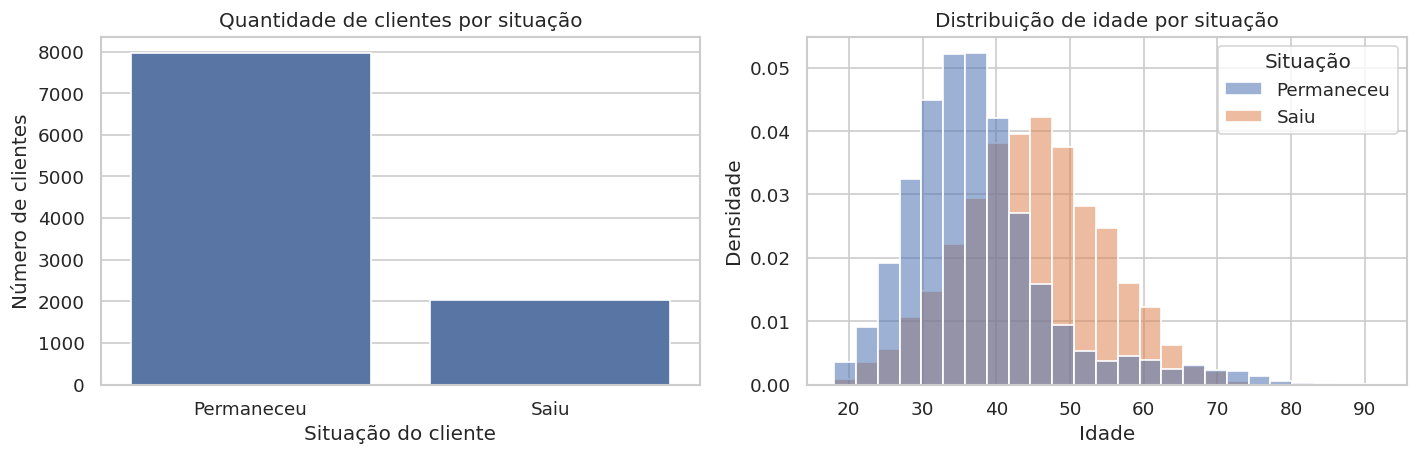

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=dados, x='Exited', ax=axes[0])
axes[0].set_title('Quantidade de clientes por situação')
axes[0].set_xlabel('Situação do cliente')
axes[0].set_ylabel('Número de clientes')
axes[0].set_xticks([0, 1], ['Permaneceu', 'Saiu'])

sns.histplot(data=dados, x='Age', hue='Exited', bins=25,
             stat='density', common_norm=False, alpha=0.55, ax=axes[1])
axes[1].set_title('Distribuição de idade por situação')
axes[1].set_xlabel('Idade')
axes[1].set_ylabel('Densidade')
if axes[1].legend_ is not None:
    axes[1].legend_.set_title('Situação')
    for texto, rotulo in zip(axes[1].legend_.texts, ['Permaneceu', 'Saiu']):
        texto.set_text(rotulo)

plt.tight_layout()

### O que os dados mostram

A classe `Saiu` é menor que a classe `Permaneceu`. Por isso, a acurácia sozinha pode dar uma impressão boa mesmo se o modelo não encontrar muitos clientes que saíram. Vou observar principalmente F1, precisão, recall e AUC-ROC.

## 2. Preparar as características e dividir os dados

Vou retirar `RowNumber`, `CustomerId` e `Surname`, que identificam registros ou pessoas, mas não ajudam de forma adequada a prever churn. `Geography` e `Gender` são categorias; vou convertê-las em colunas numéricas. Os valores ausentes de `Tenure` serão preenchidos com a mediana calculada no conjunto de treino.

A divisão será estratificada: 60% para treino, 20% para validação e 20% para teste. A validação serve para escolher a abordagem e os parâmetros. O teste ficará reservado para a avaliação final.

In [4]:
X = dados.drop(['RowNumber', 'CustomerId', 'Surname', 'Exited'], axis=1)
y = dados['Exited']

# Converter as colunas de texto em colunas numéricas (0/1).
X = pd.get_dummies(X, columns=['Geography', 'Gender'], drop_first=True, dtype=int)

X_train, X_restante, y_train, y_restante = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_restante, y_restante, test_size=0.50,
    random_state=RANDOM_STATE, stratify=y_restante
)

# Preencher Tenure usando somente a mediana do treino.
mediana_tenure = X_train['Tenure'].median()
for parte in [X_train, X_valid, X_test]:
    parte['Tenure'] = parte['Tenure'].fillna(mediana_tenure)

# Padronizar as colunas numéricas. Isso ajuda a regressão logística.
scaler = StandardScaler()
X_train_escalado = scaler.fit_transform(X_train)
X_valid_escalado = scaler.transform(X_valid)
X_test_escalado = scaler.transform(X_test)

print(f'Treino: {len(X_train)} registros')
print(f'Validação: {len(X_valid)} registros')
print(f'Teste: {len(X_test)} registros')
print(f'Mediana usada para Tenure: {mediana_tenure}')
print(f'Número de características após a codificação: {X_train.shape[1]}')

Treino: 6000 registros
Validação: 2000 registros
Teste: 2000 registros
Mediana usada para Tenure: 5.0
Número de características após a codificação: 11


## 3. Primeiro modelo: sem corrigir o desbalanceamento

Vou treinar uma regressão logística e uma floresta aleatória sem técnicas de balanceamento. Para essa primeira comparação, as previsões usam o limiar padrão de 0,50.

In [5]:
def calcular_metricas(y_real, probabilidades, limiar=0.50):
    previsoes = (probabilidades >= limiar).astype(int)
    return {
        'limiar': limiar,
        'acurácia': accuracy_score(y_real, previsoes),
        'precisão': precision_score(y_real, previsoes, zero_division=0),
        'recall': recall_score(y_real, previsoes, zero_division=0),
        'F1': f1_score(y_real, previsoes, zero_division=0),
        'AUC-ROC': roc_auc_score(y_real, probabilidades)
    }

modelos_iniciais = {
    'Regressão logística': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Floresta aleatória': RandomForestClassifier(
        n_estimators=250, max_depth=10, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    )
}
resultados_iniciais = []
for nome, modelo in modelos_iniciais.items():
    modelo.fit(X_train_escalado, y_train)
    probabilidades = modelo.predict_proba(X_valid_escalado)[:, 1]
    resultados_iniciais.append({'modelo': nome, **calcular_metricas(y_valid, probabilidades)})

# Referência simples: prever que todos permaneceram no banco.
previsoes_maioria = np.zeros(len(y_valid), dtype=int)
resultados_iniciais.append({
    'modelo': 'Baseline: sempre permaneceu',
    'limiar': 0.50,
    'acurácia': accuracy_score(y_valid, previsoes_maioria),
    'precisão': 0.0,
    'recall': 0.0,
    'F1': 0.0,
    'AUC-ROC': 0.5
})
resultados_iniciais = pd.DataFrame(resultados_iniciais).sort_values('F1', ascending=False)
resultados_iniciais

,modelo,limiar,acurácia,precisão,recall,F1,AUC-ROC
1,Floresta aleatória,0.5,0.8655,0.781377,0.473039,0.589313,0.874697
0,Regressão logística,0.5,0.8115,0.611511,0.208333,0.310786,0.787442
2,Baseline: sempre permaneceu,0.5,0.7960,0.000000,0.000000,0.000000,0.500000


### Conclusão do primeiro teste

Na validação, a floresta aleatória teve acurácia de **0,866**, mas recall de **0,473**: encontrou cerca de 47 de cada 100 clientes que saíram. A precisão foi **0,781**, então a maior parte dos clientes sinalizados realmente saiu. O F1 foi **0,589**, um pouco abaixo da meta do projeto (que será conferida no teste final). A AUC-ROC foi **0,875**, mostrando boa capacidade de ordenar clientes por risco, apesar do recall baixo no limiar 0,50.

A regressão logística teve F1 de **0,311**. Como referência simples, prever que todos permaneceram dá acurácia de cerca de **0,796**, mas F1 e recall iguais a zero: nenhum cliente que saiu seria encontrado. Por isso, a acurácia sozinha não serve para avaliar este problema.

## 4. Comparar formas de lidar com o desbalanceamento

Vou comparar quatro opções: manter os dados como estão, usar pesos de classe, aumentar a classe minoritária (oversampling) e reduzir a classe majoritária (undersampling). Para cada opção, vou testar algumas profundidades e tamanhos mínimos de folha da floresta aleatória.

Também vou escolher o limiar de decisão com os dados de validação. O limiar muda quantos clientes o modelo sinaliza como risco. Todas as estratégias serão avaliadas com a mesma divisão dos dados.

In [6]:
def balancear_treino(X_dados, y_dados, estrategia):
    if estrategia == 'sem correção' or estrategia == 'class_weight':
        return scaler.transform(X_dados), y_dados

    treino = X_dados.copy()
    treino['Exited'] = np.array(y_dados)
    clientes_sairam = treino[treino['Exited'] == 1]
    clientes_ficaram = treino[treino['Exited'] == 0]

    if estrategia == 'oversampling':
        clientes_sairam = resample(
            clientes_sairam, replace=True, n_samples=len(clientes_ficaram),
            random_state=RANDOM_STATE
        )
        treino_balanceado = pd.concat([clientes_ficaram, clientes_sairam])
    else:
        clientes_ficaram = resample(
            clientes_ficaram, replace=False, n_samples=len(clientes_sairam),
            random_state=RANDOM_STATE
        )
        treino_balanceado = pd.concat([clientes_ficaram, clientes_sairam])

    treino_balanceado = treino_balanceado.sample(frac=1, random_state=RANDOM_STATE)
    y_balanceado = treino_balanceado.pop('Exited')
    return scaler.transform(treino_balanceado), y_balanceado

def encontrar_limiar(y_real, probabilidades):
    melhor_limiar = 0.50
    melhor_f1 = 0
    for limiar in np.arange(0.20, 0.71, 0.01):
        f1 = f1_score(y_real, probabilidades >= limiar, zero_division=0)
        if f1 > melhor_f1:
            melhor_f1 = f1
            melhor_limiar = limiar
    return melhor_limiar, melhor_f1

estrategias = ['sem correção', 'class_weight', 'oversampling', 'undersampling']
resultados_validacao = []
melhor_f1_validacao = 0
melhor_modelo = None
melhor_configuracao = None

for estrategia in estrategias:
    X_balanceado, y_balanceado = balancear_treino(X_train, y_train, estrategia)
    for profundidade in [6, 10, 14]:
        for folha in [2, 5]:
            pesos = 'balanced' if estrategia == 'class_weight' else None
            modelo = RandomForestClassifier(
                n_estimators=250, max_depth=profundidade,
                min_samples_leaf=folha, class_weight=pesos,
                random_state=RANDOM_STATE, n_jobs=-1
            )
            modelo.fit(X_balanceado, y_balanceado)
            probabilidades = modelo.predict_proba(X_valid_escalado)[:, 1]
            limiar, f1_validacao = encontrar_limiar(y_valid, probabilidades)
            metricas = calcular_metricas(y_valid, probabilidades, limiar)
            resultados_validacao.append({
                'estratégia': estrategia,
                'profundidade': profundidade,
                'folha': folha,
                **metricas
            })
            if f1_validacao > melhor_f1_validacao:
                melhor_f1_validacao = f1_validacao
                melhor_modelo = modelo
                melhor_configuracao = {
                    'estratégia': estrategia,
                    'profundidade': profundidade,
                    'folha': folha,
                    'limiar': limiar
                }

resultados_validacao = pd.DataFrame(resultados_validacao)
melhores_por_estrategia = (resultados_validacao
    .sort_values('F1', ascending=False)
    .groupby('estratégia', as_index=False).first()
    .sort_values('F1', ascending=False))
melhores_por_estrategia

,estratégia,profundidade,folha,limiar,acurácia,precisão,recall,F1,AUC-ROC
3,undersampling,10,5,0.55,0.8370,0.575926,0.762255,0.656118,0.866806
2,sem correção,10,2,0.37,0.8700,0.715116,0.602941,0.654255,0.874697
0,class_weight,10,5,0.46,0.8385,0.581262,0.745098,0.653061,0.874119
1,oversampling,10,2,0.51,0.8485,0.614379,0.691176,0.650519,0.869473


### O que a validação indica

O undersampling teve o maior F1 (**0,656**), com recall de **0,762**. Isso significa que encontrou mais clientes que saíram, mas sua precisão (**0,576**) foi menor. Sem corrigir o desequilíbrio, mas ajustando o limiar para 0,37, o modelo chegou a F1 **0,654** e teve a maior AUC-ROC (**0,875**). Class weight e oversampling ficaram próximos, com F1 de **0,653** e **0,651**.

A diferença entre o maior F1 e o resultado sem correção foi de apenas **0,002**. Com esses dados, não dá para afirmar que undersampling é sempre melhor. O ajuste do limiar parece ter contribuído bastante: a floresta aleatória inicial tinha F1 **0,589** no limiar 0,50. Vou seguir com a configuração de maior F1 na validação, registrando que o resultado ficou muito próximo das outras opções. O teste ainda não foi usado para essa escolha.

In [7]:
print('Melhor configuração escolhida na validação:')
print(melhor_configuracao)

# Comparar o F1 do melhor resultado de cada estratégia com o modelo inicial.
f1_inicial_floresta = resultados_iniciais.loc[
    resultados_iniciais['modelo'] == 'Floresta aleatória', 'F1'
].iloc[0]
melhores_por_estrategia['diferença para a floresta inicial'] = (
    melhores_por_estrategia['F1'] - f1_inicial_floresta
)
melhores_por_estrategia[['estratégia', 'F1', 'precisão', 'recall', 'AUC-ROC',
                          'limiar', 'diferença para a floresta inicial']]

Melhor configuração escolhida na validação:
{'estratégia': 'undersampling', 'profundidade': 10, 'folha': 5, 'limiar': np.float64(0.5500000000000003)}


## 5. Teste final

Agora vou avaliar no teste o mesmo modelo treinado no conjunto de treino e selecionado pela validação. Assim, o limiar foi escolhido e o teste continua separado. Não vou retreinar o modelo com treino e validação antes de aplicar esse limiar, pois a distribuição das probabilidades poderia mudar.

In [8]:
probabilidades_teste = melhor_modelo.predict_proba(X_test_escalado)[:, 1]
previsoes_teste = (probabilidades_teste >= melhor_configuracao['limiar']).astype(int)
metricas_teste = calcular_metricas(
    y_test, probabilidades_teste, melhor_configuracao['limiar']
)

print('Configuração final:', melhor_configuracao)
print(pd.Series(metricas_teste, name='resultado no teste'))
print('Matriz de confusão (linhas = valor real; colunas = previsão):')
print(confusion_matrix(y_test, previsoes_teste))

Configuração final: {'estratégia': 'undersampling', 'profundidade': 10, 'folha': 5, 'limiar': np.float64(0.5500000000000003)}
limiar      0.550000
acurácia    0.812000
precisão    0.529081
recall      0.692875
F1          0.600000
AUC-ROC     0.853274
Name: resultado no teste, dtype: float64
Matriz de confusão (linhas = valor real; colunas = previsão):
[[1342  251]
 [ 125  282]]


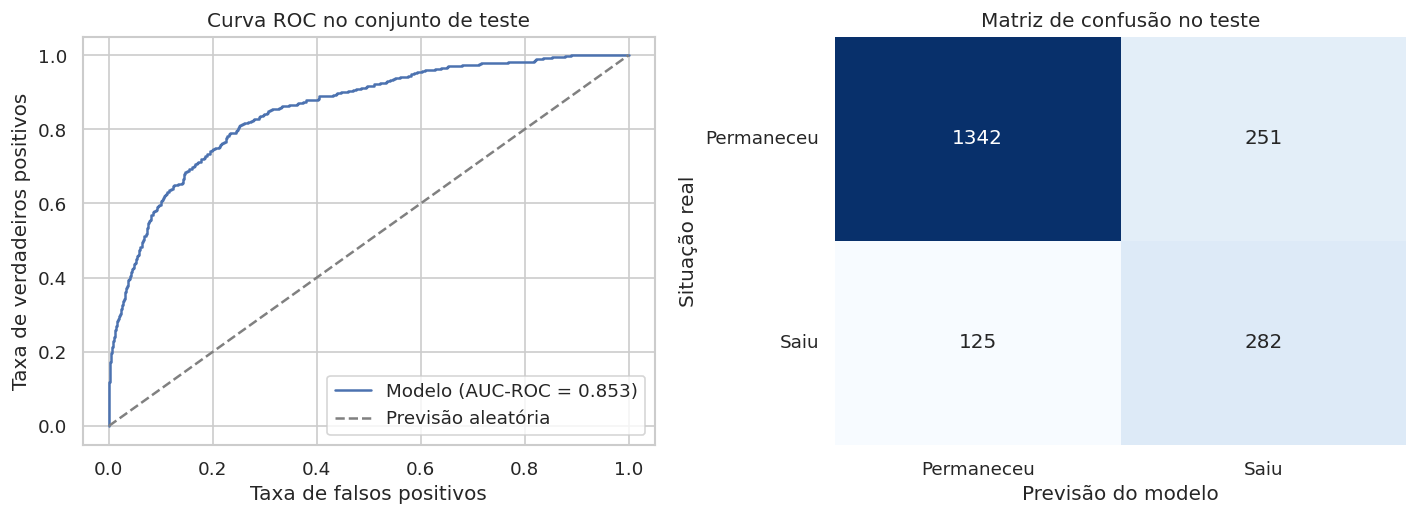

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
falsos_positivos, verdadeiros_positivos, _ = roc_curve(y_test, probabilidades_teste)
axes[0].plot(falsos_positivos, verdadeiros_positivos,
             label=f"Modelo (AUC-ROC = {metricas_teste['AUC-ROC']:.3f})")
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Previsão aleatória')
axes[0].set_title('Curva ROC no conjunto de teste')
axes[0].set_xlabel('Taxa de falsos positivos')
axes[0].set_ylabel('Taxa de verdadeiros positivos')
axes[0].legend()

matriz = confusion_matrix(y_test, previsoes_teste)
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1])
axes[1].set_title('Matriz de confusão no teste')
axes[1].set_xlabel('Previsão do modelo')
axes[1].set_ylabel('Situação real')
axes[1].set_xticklabels(['Permaneceu', 'Saiu'])
axes[1].set_yticklabels(['Permaneceu', 'Saiu'], rotation=0)
plt.tight_layout()

## 6. Conclusão

No teste, a configuração escolhida alcançou F1 **0,600**, acima da meta de **0,590**, e AUC-ROC **0,853**. A precisão foi **0,529** e o recall **0,693**. Pela matriz de confusão, o modelo encontrou 282 dos 407 clientes que saíram e deixou passar 125. Também sinalizou 251 clientes que permaneceram.

F1 resume o equilíbrio entre precisão e recall para identificar quem saiu. AUC-ROC mede a capacidade de ordenar clientes por risco em vários limiares; ela não garante, sozinha, um F1 alto no limiar escolhido. O resultado supera a meta por **0,010**, uma margem pequena, então não convém prometer desempenho maior do que os dados mostram.

Em uma operação real, o banco ainda precisaria decidir quantos clientes consegue contatar e quanto custam os falsos alarmes e as saídas não identificadas. Esta base não tem datas, então não foi possível fazer uma validação temporal. Também não é possível concluir que uma ação de retenção evitará o churn apenas com esta análise.